# 04 — Feature Engineering y exploración de variables

Objetivo: crear variables derivadas y explorar importancia, selección de características y PCA. Este notebook no pretende ser la comparación definitiva de todos los modelos.

## Carga de datos y preparación

Este bloque reproduce la división usada en los experimentos. Ejecutá el notebook desde la raíz del proyecto para que la ruta relativa funcione.

In [1]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split

df_fe = pd.read_csv("../data/processed/airbnb_dp.csv")

X = df_fe.drop(columns=["price"])
y = df_fe["price"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)


X_train: (19140, 136)
X_test: (4786, 136)


## 1. Ingeniería de variables

Se crean variables derivadas de la capacidad del alojamiento y de sus amenities. La comparación se realiza con el mismo conjunto de entrenamiento y test. Para evitar inconsistencias, las funciones de creación se aplican por separado a `X_train` y `X_test`, sin usar el objetivo.

In [2]:
import numpy as np


def crear_features_capacidad(df):
    df = df.copy()

    # Capacidad y tamaño del alojamiento
    if {"beds", "accommodates"}.issubset(df.columns):
        df["beds_per_guest"] = df["beds"] / df["accommodates"].replace(0, np.nan)

    if {"bedrooms", "accommodates"}.issubset(df.columns):
        df["bedrooms_per_guest"] = df["bedrooms"] / df["accommodates"].replace(
            0, np.nan
        )

    if {"bathrooms", "accommodates"}.issubset(df.columns):
        df["bathrooms_per_guest"] = df["bathrooms"] / df["accommodates"].replace(
            0, np.nan
        )

    if {"beds", "bedrooms"}.issubset(df.columns):
        df["beds_per_bedroom"] = df["beds"] / df["bedrooms"].replace(0, np.nan)

    # Cantidad de amenities entre las 20 seleccionadas
    amenities = [
        "Kitchen",
        "Wifi",
        "Hot water",
        "Dishes and silverware",
        "Cooking basics",
        "Hangers",
        "Bed linens",
        "Hair dryer",
        "Refrigerator",
        "Microwave",
        "Bidet",
        "Air conditioning",
        "Essentials",
        "Hot water kettle",
        "Elevator",
        "Room-darkening shades",
        "TV",
        "Dedicated workspace",
        "Iron",
        "Extra pillows and blankets",
    ]

    amenities_presentes = [col for col in amenities if col in df.columns]

    if amenities_presentes:
        df["amenities_count"] = df[amenities_presentes].sum(axis=1)

    return df


X_train_fe = crear_features_capacidad(X_train)
X_test_fe = crear_features_capacidad(X_test)

print("Columnas originales:", X_train.shape[1])
print("Columnas con feature engineering:", X_train_fe.shape[1])


Columnas originales: 136
Columnas con feature engineering: 141


In [3]:
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

# Utilizar los mejores parámetros encontrados en tu búsqueda.
# Reemplazá estos valores por los de search.best_params_
# si son diferentes.
parametros = {
    "learning_rate": 0.068,
    "max_iter": 140,
    "max_leaf_nodes": 38,
    "min_samples_leaf": 24,
    "l2_regularization": 7.87,
    "random_state": 42,
}


def evaluar_modelo(Xtr, ytr, Xte, yte):
    modelo = HistGradientBoostingRegressor(**parametros)
    modelo.fit(Xtr, ytr)
    pred = modelo.predict(Xte)

    return {
        "R2": r2_score(yte, pred),
        "RMSE": np.sqrt(mean_squared_error(yte, pred)),
        "MAE": mean_absolute_error(yte, pred),
    }


resultados = {
    "Original": evaluar_modelo(X_train, y_train, X_test, y_test),
    "Feature Engineering": evaluar_modelo(X_train_fe, y_train, X_test_fe, y_test),
}

display(pd.DataFrame(resultados).T)


,R2,RMSE,MAE
Original,0.507533,65395.187527,35017.634438
Feature Engineering,0.510501,65197.790099,34976.247294


## Evaluación de nuevas variables derivadas

Se agregaron cinco características basadas en la capacidad del alojamiento y en sus amenities: `beds_per_guest`, `bedrooms_per_guest`, `bathrooms_per_guest`, `beds_per_bedroom` y `amenities_count`. Las divisiones por cero se convierten en valores faltantes para evitar cocientes indefinidos.

Con los mismos hiperparámetros de HistGradientBoosting, la comparación registrada fue:

| Versión | Variables | R² test | RMSE | MAE |
|---|---:|---:|---:|---:|
| Original | 136 | 0,5075 | 65.395,19 | 35.017,63 |
| Con feature engineering | 141 | **0,5105** | **65.197,79** | **34.976,25** |

La mejora es pequeña pero positiva en las tres métricas. Es un resultado prometedor para explorar, no una prueba definitiva de mejora generalizable; la comparación usa el conjunto de test y conviene confirmarla con validación cruzada dentro del entrenamiento.


## 2. Importancia por permutación

La importancia por permutación mide cuánto cae la métrica del modelo al desordenar una variable. Es una medida de utilidad predictiva en esta configuración, no de causalidad.

## Importancia por permutación

Se ajustó HistGradientBoosting sobre una parte de `X_train` y se calculó permutation importance en una validación interna. La importancia mide cuánto empeora el R² cuando se permuta una característica; cuanto mayor es la caída, más útil resultó esa característica para este modelo y esa partición.

Entre las variables con mayor importancia aparecen `bathrooms`, `bedrooms`, `accommodates`, `latitude`, `min_nights`, `availability_365`, `room_type_Entire home/apt` y `longitude`. Esto sugiere que las características relacionadas con tamaño/capacidad y ubicación tienen un papel relevante. La importancia es específica del modelo y de la partición utilizada: no demuestra causalidad.


In [4]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import r2_score

# Separar una validación interna dentro del entrenamiento
X_fit, X_val, y_fit, y_val = train_test_split(
    X_train, y_train, test_size=0.2, random_state=42
)

# Usar los mejores parámetros que encontraste para Hist Gradient Boosting
modelo_importancia = HistGradientBoostingRegressor(
    learning_rate=0.068,
    max_iter=140,
    max_leaf_nodes=38,
    min_samples_leaf=24,
    l2_regularization=7.87,
    random_state=42,
)

modelo_importancia.fit(X_fit, y_fit)

# Calcular importancia por permutación en la validación interna
importancias = permutation_importance(
    modelo_importancia,
    X_val,
    y_val,
    scoring="r2",
    n_repeats=5,
    random_state=42,
    n_jobs=-1,
)

df_importancias = pd.DataFrame(
    {
        "feature": X_val.columns,
        "importance_mean": importancias.importances_mean,
        "importance_std": importancias.importances_std,
    }
).sort_values("importance_mean", ascending=False)

display(df_importancias.head(30))


,feature,importance_mean,importance_std
112,bathrooms,0.210593,0.006664
4,bedrooms,0.131356,0.008080
3,accommodates,0.117927,0.007030
1,latitude,0.067330,0.001735
6,min_nights,0.038273,0.003190
8,availability_365,0.037073,0.002419
62,room_type_Entire home/apt,0.029736,0.003116
2,longitude,0.016582,0.003340
9,number_of_reviews,0.014193,0.002469
10,review_scores_rating,0.010553,0.002780


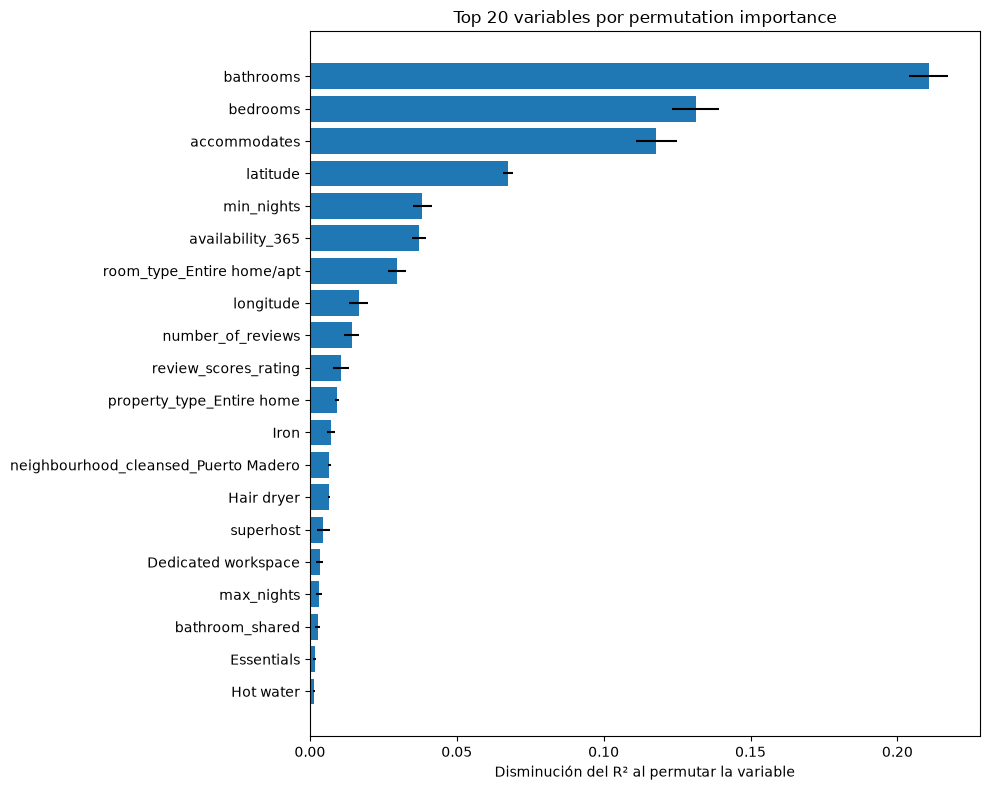

In [5]:
import matplotlib.pyplot as plt

top_features = df_importancias.head(20).sort_values("importance_mean")

plt.figure(figsize=(10, 8))

plt.barh(
    top_features["feature"],
    top_features["importance_mean"],
    xerr=top_features["importance_std"],
)

plt.xlabel("Disminución del R² al permutar la variable")
plt.title("Top 20 variables por permutation importance")
plt.tight_layout()
plt.show()


## 3. Selección exploratoria por ranking

Esta prueba compara subconjuntos de las variables ordenadas por importancia. Los resultados basados en test son exploratorios; no se deben usar para estimar de forma imparcial el rendimiento final.

### Prueba exploratoria con los primeros *k* atributos

Se ordenaron las variables según su importancia por permutación y se entrenó HistGradientBoosting con los primeros 10, 20, 30, 50, 75 y 136 atributos. En este experimento, el mejor R² de test entre los subconjuntos probados fue aproximadamente 0,5087 con 75 variables; con 30 se obtuvo 0,5070. La diferencia frente al modelo completo es pequeña.

**Precaución:** elegir `k` mirando los resultados de test introduce sesgo de selección. Estos números deben considerarse exploratorios, no una comparación final independiente. Las siguientes pruebas incorporan la selección dentro de un `Pipeline` y de la validación cruzada.


In [6]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Orden de variables por importancia
ranking_features = df_importancias["feature"].tolist()

# Modelo completo de referencia
parametros = {
    "learning_rate": 0.068,
    "max_iter": 140,
    "max_leaf_nodes": 38,
    "min_samples_leaf": 24,
    "l2_regularization": 7.87,
    "random_state": 42,
}

tamanos = [10, 20, 30, 50, 75, len(ranking_features)]
tamanos = sorted(set(k for k in tamanos if 1 <= k <= len(ranking_features)))

resultados_fs = []

for k in tamanos:
    features = ranking_features[:k]

    modelo = HistGradientBoostingRegressor(**parametros)
    modelo.fit(X_train[features], y_train)

    pred = modelo.predict(X_test[features])

    resultados_fs.append(
        {
            "n_features": k,
            "R2": r2_score(y_test, pred),
            "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
            "MAE": mean_absolute_error(y_test, pred),
        }
    )

resultados_fs = pd.DataFrame(resultados_fs)
display(resultados_fs)


,n_features,R2,RMSE,MAE
0,10,0.484176,66928.016006,36591.299794
1,20,0.503847,65639.453541,35379.408766
2,30,0.507037,65428.115968,35178.038445
3,50,0.506556,65459.988675,35187.673953
4,75,0.508725,65315.961141,35125.533713
5,136,0.507533,65395.187527,35017.634438


## 4. Reducción de dimensionalidad con PCA

PCA crea componentes que combinan las variables originales. El escalado y PCA se ajustan dentro del pipeline y de cada fold de validación.

## Reducción de dimensionalidad con PCA

PCA transforma las variables originales en componentes que capturan la varianza de los predictores. Antes de PCA se aplica `StandardScaler` dentro de un `Pipeline`, evitando ajustar el escalador o PCA por separado antes de la validación cruzada. Se probaron niveles del 90 %, 95 % y 99 % de varianza conservada para Ridge y SVR.

| Modelo | PCA | Componentes | CV R² | Test R² | RMSE | MAE |
|---|---|---:|---:|---:|---:|---:|
| Ridge | Sin PCA | 136 | 0,4070 | **0,4129** | **71.403,40** | **41.209,87** |
| Ridge | 90 % | 100 | 0,3761 | 0,3745 | 73.699,60 | 42.672,99 |
| Ridge | 95 % | 110 | 0,3845 | 0,3869 | 72.968,07 | 42.207,37 |
| Ridge | 99 % | 120 | 0,3866 | 0,3889 | 72.844,58 | 41.905,97 |
| SVR | Sin PCA | 136 | -0,0602 | -0,0609 | 95.984,39 | 52.618,55 |
| SVR | 90 % | 100 | -0,0601 | -0,0608 | 95.977,84 | 52.608,61 |
| SVR | 95 % | 110 | -0,0602 | -0,0608 | 95.978,30 | 52.613,41 |
| SVR | 99 % | 120 | -0,0602 | -0,0609 | 95.983,07 | 52.617,87 |

### Interpretación de PCA

En Ridge, PCA redujo el rendimiento frente a la versión sin PCA. Para SVR los resultados permanecieron prácticamente iguales y el R² negativo indica que, en este experimento, el modelo rindió peor que predecir una constante igual al promedio del target. Por tanto, PCA no aporta una mejora en estas pruebas. Esto no demuestra que PCA nunca sirva: el resultado depende del modelo, las variables y la configuración.


In [7]:
import pandas as pd
import numpy as np

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import Ridge
from sklearn.svm import SVR
from sklearn.model_selection import cross_val_score
from sklearn.metrics import r2_score, mean_absolute_error, root_mean_squared_error

# Porcentajes de varianza que queremos conservar
pca_variances = [0.90, 0.95, 0.99]

results = []

models = {"Ridge": Ridge(alpha=100), "SVR": SVR(kernel="rbf", C=1.0, epsilon=0.1)}

# Modelos de referencia: sin PCA
for model_name, model in models.items():
    baseline = Pipeline([("scaler", StandardScaler()), ("model", model)])

    cv_scores = cross_val_score(
        baseline, X_train, y_train, cv=3, scoring="r2", n_jobs=-1
    )

    baseline.fit(X_train, y_train)
    y_pred = baseline.predict(X_test)

    results.append(
        {
            "Modelo": model_name,
            "PCA": "Sin PCA",
            "Componentes": X_train.shape[1],
            "Varianza conservada": 1.0,
            "CV R2": cv_scores.mean(),
            "Test R2": r2_score(y_test, y_pred),
            "RMSE": root_mean_squared_error(y_test, y_pred),
            "MAE": mean_absolute_error(y_test, y_pred),
        }
    )

# Modelos con PCA
for variance in pca_variances:
    for model_name, model in models.items():
        pipeline = Pipeline(
            [
                ("scaler", StandardScaler()),
                ("pca", PCA(n_components=variance)),
                ("model", model),
            ]
        )

        cv_scores = cross_val_score(
            pipeline, X_train, y_train, cv=3, scoring="r2", n_jobs=-1
        )

        pipeline.fit(X_train, y_train)
        y_pred = pipeline.predict(X_test)

        n_components = pipeline.named_steps["pca"].n_components_

        results.append(
            {
                "Modelo": model_name,
                "PCA": f"{variance:.0%}",
                "Componentes": n_components,
                "Varianza conservada": variance,
                "CV R2": cv_scores.mean(),
                "Test R2": r2_score(y_test, y_pred),
                "RMSE": root_mean_squared_error(y_test, y_pred),
                "MAE": mean_absolute_error(y_test, y_pred),
            }
        )

results_df = pd.DataFrame(results)

results_df.sort_values(by="CV R2", ascending=False).round(4)


,Modelo,PCA,Componentes,Varianza conservada,CV R2,Test R2,RMSE,MAE
0,Ridge,Sin PCA,136,1.00,0.4070,0.4129,71403.3974,41209.8727
6,Ridge,99%,120,0.99,0.3866,0.3889,72844.5818,41905.9728
4,Ridge,95%,110,0.95,0.3845,0.3869,72968.0723,42207.3705
2,Ridge,90%,100,0.90,0.3761,0.3745,73699.5993,42672.9861
3,SVR,90%,100,0.90,-0.0601,-0.0608,95977.8352,52608.6110
5,SVR,95%,110,0.95,-0.0602,-0.0608,95978.3011,52613.4113
7,SVR,99%,120,0.99,-0.0602,-0.0609,95983.0689,52617.8712
1,SVR,Sin PCA,136,1.00,-0.0602,-0.0609,95984.3925,52618.5503


## Conclusiones del notebook 04

- Se exploraron variables derivadas y la importancia de características.
- La selección por importancia y PCA se trataron como experimentos exploratorios.
- Los modelos y sus hiperparámetros se comparan sistemáticamente en el notebook 05; las búsquedas de hiperparámetros se concentran en el notebook 06.